# Smart Factory AI Monitoring System

## Project Overview

### Problem Statement

In manufacturing industries, worker safety is very important. Supervisors manually monitor workers to ensure they wear safety equipment such as helmets and safety vests and avoid entering hazardous areas. This process is time-consuming and may lead to human errors.

This project uses Artificial Intelligence and Computer Vision to automate worker safety monitoring using CCTV camera feeds.

---

## Objectives

- Detect workers in real time.
- Detect safety helmets and safety vests.
- Count the number of workers.
- Detect if a worker enters a restricted area.
- Display violations in real time.
- Store violation records in a database.
- Create a dashboard for monitoring.

---

## Technologies Used

- Python
- OpenCV
- YOLOv11 (Ultralytics)
- NumPy
- Pandas
- SQLite
- Streamlit
- VS Code
- GitHub

---

## Expected Output

The system should:

✔ Detect workers

✔ Detect helmets

✔ Detect safety vests

✔ Count workers

✔ Highlight danger zone violations

✔ Save violation history

✔ Display a dashboard

# Project Workflow

Camera / Video

↓

OpenCV captures frames

↓

YOLO detects objects

↓

Safety Rule Engine

↓

Violation Detection

↓

SQLite Database

↓

Streamlit Dashboard

### Import Libraries

In [8]:
import os
import cv2   # processes images and videos.
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO  #object detection model.

In [9]:
model = YOLO("yolo11n.pt")
print("YOLOv11 Nano Model Loaded Successfully!")

YOLOv11 Nano Model Loaded Successfully!


In [10]:
print(model.model)

DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C3k2(
      (cv1): Conv(
        (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
   

#### Creating Floders

In [11]:
folders = [

    "dataset",

    "models",

    "notebooks",

    "src",

    "database",

    "output",

    "output/images",

    "output/videos"

]

for folder in folders:

    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully.")

Project folders created successfully.


In [12]:
results = model.predict(

    source="https://ultralytics.com/images/bus.jpg",

    save=False,

    conf=0.4

)

print("YOLO Prediction Successful")


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 c:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\notebooks\bus.jpg: 640x480 4 persons, 1 bus, 108.7ms
Speed: 3.9ms preprocess, 108.7ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 480)
YOLO Prediction Successful


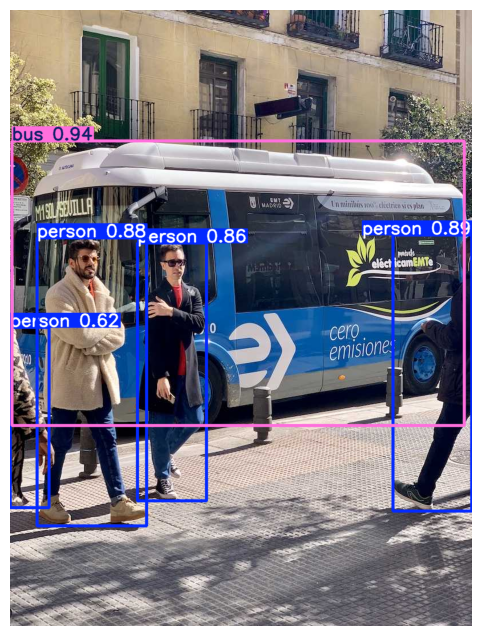

In [13]:
annotated = results[0].plot()

plt.figure(figsize=(10,8))

plt.imshow(cv2.cvtColor(annotated,cv2.COLOR_BGR2RGB))

plt.axis("off")

plt.show()

In [14]:
import sys


print("="*50)

print("ENVIRONMENT SUMMARY")

print("="*50)

print("Python :", sys.version)

print("OpenCV :", cv2.__version__)

print("PyTorch :", torch.__version__)

print("NumPy :", np.__version__)

print("CUDA :", torch.cuda.is_available())

print("="*50)

ENVIRONMENT SUMMARY
Python : 3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]
OpenCV : 4.13.0


NameError: name 'torch' is not defined

In [ ]:
model.info()

YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


(100, 2616248, 0, 6.4835199999999995)

## Data Collection & Dataset Preparation

crating data.yaml file

In [ ]:
dataset_info = {

    "path": "dataset",

    "train": "train/images",

    "val": "valid/images",

    "test": "test/images",

    "names": [

        "Hardhat",

        "Mask",

        "NO-Hardhat",

        "NO-Mask",

        "NO-Safety Vest",

        "Person",

        "Safety Cone",

        "Safety Vest",

        "machinery",

        "vehicle"

    ]

}

with open("dataset/data.yaml", "w") as file:

    yaml.dump(dataset_info, file, sort_keys=False)

print("data.yaml created successfully")

data.yaml created successfully


In [ ]:
import os

label_folder = "dataset/train/labels"

classes = set()

for file in os.listdir(label_folder):
    if file.endswith(".txt"):
        with open(os.path.join(label_folder, file), "r") as f:
            for line in f:
                class_id = int(line.split()[0])
                classes.add(class_id)

print("Classes found:", sorted(classes))
print("Total classes:", len(classes))

Classes found: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Total classes: 10


In [ ]:
import os

folders = [
    "dataset/train/images",
    "dataset/train/labels",
    "dataset/valid/images",
    "dataset/valid/labels",
    "dataset/test/images",
    "dataset/test/labels"
]

for folder in folders:
    if os.path.exists(folder):
        print(f"✅ {folder} exists")
        print(f"   Files: {len(os.listdir(folder))}")
    else:
        print(f"❌ {folder} NOT FOUND")

✅ dataset/train/images exists
   Files: 2605
✅ dataset/train/labels exists
   Files: 2605
✅ dataset/valid/images exists
   Files: 114
✅ dataset/valid/labels exists
   Files: 114
✅ dataset/test/images exists
   Files: 82
✅ dataset/test/labels exists
   Files: 82


In [ ]:
# read data.yaml
with open("dataset/data.yaml") as file:

    config = yaml.safe_load(file)

config

{'path': 'dataset',
 'train': 'train/images',
 'val': 'valid/images',
 'test': 'test/images',
 'names': ['Hardhat',
  'Mask',
  'NO-Hardhat',
  'NO-Mask',
  'NO-Safety Vest',
  'Person',
  'Safety Cone',
  'Safety Vest',
  'machinery',
  'vehicle']}

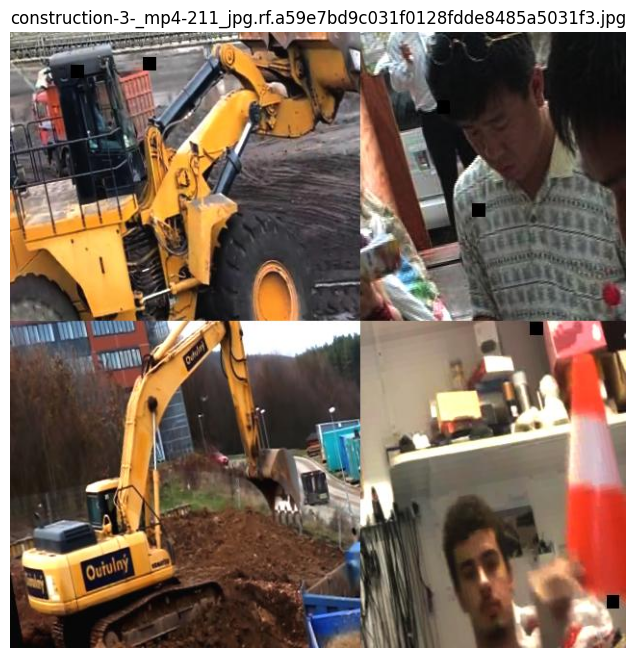

In [ ]:
# Display random training images
image_name = random.choice(os.listdir("dataset/train/images"))

image_path = os.path.join("dataset/train/images", image_name)

image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8,8))

plt.imshow(image)

plt.title(image_name)

plt.axis("off")

plt.show()

In [ ]:
# Display image information
print("Image Name :", image_name)

print("Image Shape :", image.shape)

print("Height :", image.shape[0])

print("Width :", image.shape[1])

print("Channels :", image.shape[2])

Image Name : construction-3-_mp4-211_jpg.rf.a59e7bd9c031f0128fdde8485a5031f3.jpg
Image Shape : (640, 640, 3)
Height : 640
Width : 640
Channels : 3


In [ ]:
# Read label file 

label_name = image_name.replace(".jpg", ".txt")

label_name = label_name.replace(".png", ".txt")

label_path = os.path.join("dataset/train/labels", label_name)

with open(label_path) as file:

    labels = file.readlines()

print(labels)

['8 0.1409961420797229 0.128125 0.2419521924256241 0.228125\n', '8 0.284375 0.234375 0.56875 0.46875\n', '2 0.1349370396203949 0.0953125 0.01572499394987581 0.0171875\n', '3 0.14030125049097925 0.11328125 0.012590903590796287 0.015625\n', '5 0.15345978064340446 0.134375 0.05533291549465282 0.1109375\n', '4 0.14794557884800633 0.1421875 0.022138620413308985 0.0453125\n', '9 0.6720012232654204 0.1703125 0.18312261397040128 0.321875\n', '2 0.759375 0.08125 0.228125 0.1625\n', '2 0.9125 0.1109375 0.175 0.221875\n', '3 0.8289233889564649 0.1890625 0.11477154800821018 0.121875\n', '4 0.86796875 0.03359375 0.1015625 0.0671875\n', '4 0.6671875 0.0671875 0.096875 0.134375\n', '4 0.853125 0.31640625 0.29375 0.3046875\n', '5 0.65234375 0.25625 0.1671875 0.425\n', '5 0.9140625 0.234375 0.171875 0.46875\n', '5 0.86640625 0.053125 0.1234375 0.10625\n', '5 0.68671875 0.17109375 0.1984375 0.3421875\n', '5 0.821875 0.234375 0.35625 0.46875\n', '8 0.51328125 0.89921875 0.1109375 0.2015625\n', '9 0.33911

In [ ]:
# parse YOLO labels

for label in labels:

    values = label.split()

    class_id = int(values[0])

    x_center = float(values[1])

    y_center = float(values[2])

    width = float(values[3])

    height = float(values[4])

    print("-----------------------")

    print("Class :", config["names"][class_id])

    print("Center :", (x_center, y_center))

    print("Width :", width)

    print("Height :", height)

-----------------------
Class : machinery
Center : (0.1409961420797229, 0.128125)
Width : 0.2419521924256241
Height : 0.228125
-----------------------
Class : machinery
Center : (0.284375, 0.234375)
Width : 0.56875
Height : 0.46875
-----------------------
Class : NO-Hardhat
Center : (0.1349370396203949, 0.0953125)
Width : 0.01572499394987581
Height : 0.0171875
-----------------------
Class : NO-Mask
Center : (0.14030125049097925, 0.11328125)
Width : 0.012590903590796287
Height : 0.015625
-----------------------
Class : Person
Center : (0.15345978064340446, 0.134375)
Width : 0.05533291549465282
Height : 0.1109375
-----------------------
Class : NO-Safety Vest
Center : (0.14794557884800633, 0.1421875)
Width : 0.022138620413308985
Height : 0.0453125
-----------------------
Class : vehicle
Center : (0.6720012232654204, 0.1703125)
Width : 0.18312261397040128
Height : 0.321875
-----------------------
Class : NO-Hardhat
Center : (0.759375, 0.08125)
Width : 0.228125
Height : 0.1625
-----------

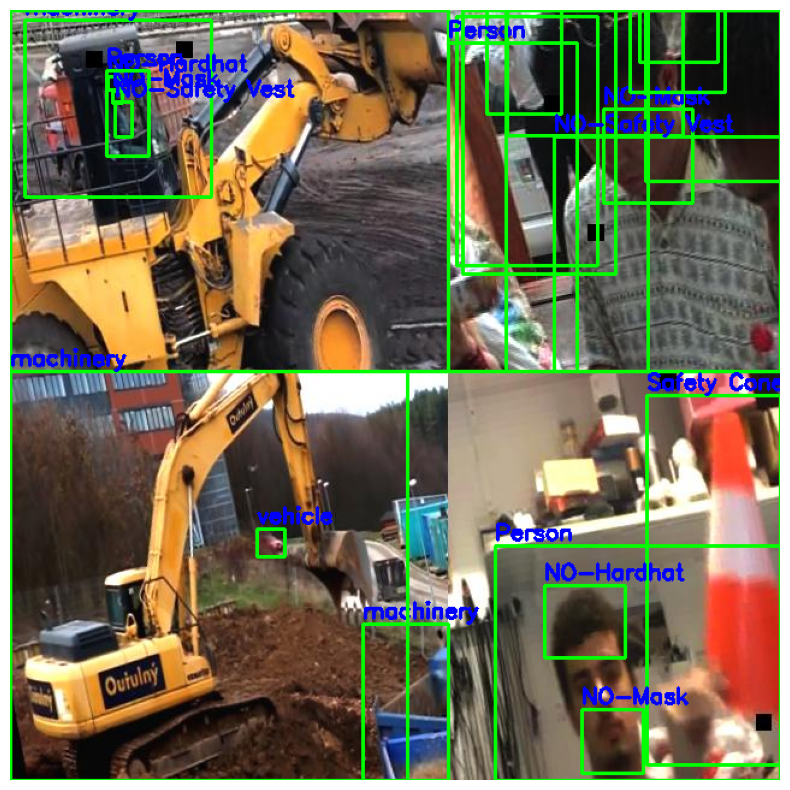

In [ ]:
# Draw Bounding Boxes

image = cv2.imread(image_path)

h, w = image.shape[:2]

for label in labels:

    values = label.split()

    class_id = int(values[0])

    x = float(values[1])

    y = float(values[2])

    bw = float(values[3])

    bh = float(values[4])

    xmin = int((x - bw / 2) * w)
    ymin = int((y - bh / 2) * h)

    xmax = int((x + bw / 2) * w)
    ymax = int((y + bh / 2) * h)

    cv2.rectangle(image,
                  (xmin, ymin),
                  (xmax, ymax),
                  (0,255,0),
                  2)

    cv2.putText(image,
                config["names"][class_id],
                (xmin, ymin-5),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255,0,0),
                2)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,10))

plt.imshow(image)

plt.axis("off")

plt.show()

## Training the YOLO11 Model

In [ ]:
results = model.train(

    data="dataset/data.yaml",

    epochs=7,

    imgsz=416,

    batch=4,

    workers=2,

    device="cpu",

    project="models",

    name="helmet_detection",

    exist_ok=True,

    pretrained=True,

    verbose=True
)



Ultralytics 8.4.92  Python-3.11.5 torch-2.11.0+cpu CPU (11th Gen Intel Core i3-1115G4 @ 3.00GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=7, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=models/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_detection, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto

In [ ]:
print("Training Completed Successfully")

Training Completed Successfully


In [ ]:
print("Classes Learned by Model:\n")

for key, value in model.names.items():
    print(f"{key} : {value}")

Classes Learned by Model:

0 : Hardhat
1 : Mask
2 : NO-Hardhat
3 : NO-Mask
4 : NO-Safety Vest
5 : Person
6 : Safety Cone
7 : Safety Vest
8 : machinery
9 : vehicle


### Load trained model


In [ ]:
from ultralytics import YOLO

model = YOLO("models/best.pt")

print("Model Loaded Successfully")

Model Loaded Successfully


In [ ]:
# Select a Test Image 
IMAGE_PATH = "dataset/test/images/" + os.listdir("dataset/test/images")[7]

print(IMAGE_PATH)

dataset/test/images/006672_jpg.rf.87d5978c486feb53177408cf00a0d87f.jpg


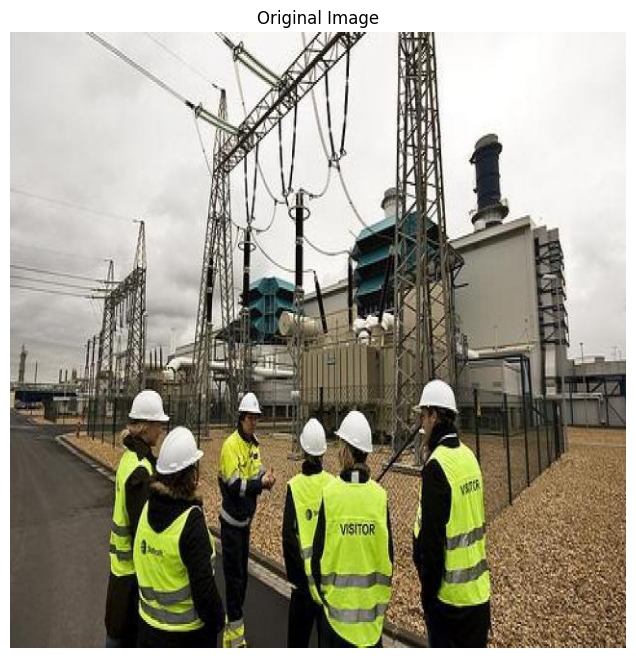

In [ ]:
# Display Original Image
image = cv2.imread(IMAGE_PATH)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,8))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [ ]:
# Run Prediction
results = model.predict(
    source=IMAGE_PATH,
    conf=0.4,
    save=False
)

print("Prediction Completed")


image 1/1 c:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\dataset\test\images\006672_jpg.rf.87d5978c486feb53177408cf00a0d87f.jpg: 416x416 7 Hardhats, 5 Persons, 4 Safety Vests, 81.8ms
Speed: 5.3ms preprocess, 81.8ms inference, 4.2ms postprocess per image at shape (1, 3, 416, 416)
Prediction Completed


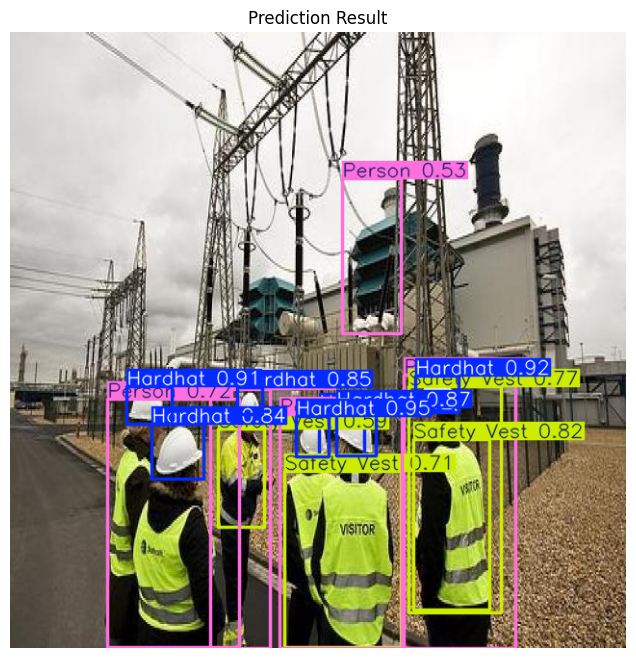

In [ ]:
# Display Predicction

annotated = results[0].plot()

plt.figure(figsize=(12,8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("Prediction Result")
plt.axis("off")
plt.show()

In [ ]:
# Print detected objects

print("Detected Objects\n")

for box in results[0].boxes:

    class_id = int(box.cls)

    confidence = float(box.conf)

    print(
        model.names[class_id],
        " | Confidence:",
        round(confidence,2)
    )

Detected Objects

Hardhat  | Confidence: 0.95
Hardhat  | Confidence: 0.92
Hardhat  | Confidence: 0.91
Hardhat  | Confidence: 0.87
Hardhat  | Confidence: 0.85
Hardhat  | Confidence: 0.84
Safety Vest  | Confidence: 0.82
Person  | Confidence: 0.78
Safety Vest  | Confidence: 0.77
Person  | Confidence: 0.72
Person  | Confidence: 0.72
Safety Vest  | Confidence: 0.71
Person  | Confidence: 0.67
Safety Vest  | Confidence: 0.59
Person  | Confidence: 0.53
Hardhat  | Confidence: 0.42


In [ ]:
# Count Objects

from collections import Counter

counter = Counter()

for box in results[0].boxes:

    class_name = model.names[int(box.cls)]

    counter[class_name] += 1

print(counter)

Counter({'Hardhat': 7, 'Person': 5, 'Safety Vest': 4})


In [ ]:
# Display Detection Summary

print("="*40)

print("Detection Summary")

print("="*40)

for key, value in counter.items():

    print(f"{key:<20}{value}")

print("="*40)

Detection Summary
Hardhat             7
Safety Vest         4
Person              5


In [ ]:
# Save predictoion image

OUTPUT_PATH = "output/images"

os.makedirs(OUTPUT_PATH, exist_ok=True)

results = model.predict(
    source=IMAGE_PATH,
    save=True,
    project="output",
    name="images",
    exist_ok=True
)

print("Prediction Image Saved Successfully")


image 1/1 c:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\dataset\test\images\006672_jpg.rf.87d5978c486feb53177408cf00a0d87f.jpg: 416x416 7 Hardhats, 6 Persons, 6 Safety Vests, 1 machinery, 253.5ms
Speed: 28.7ms preprocess, 253.5ms inference, 2.1ms postprocess per image at shape (1, 3, 416, 416)
Results saved to C:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\runs\detect\output\images
Prediction Image Saved Successfully


In [ ]:
print(os.listdir("output/images"))

[]


In [ ]:
# Multiple Image Pridection 

TEST_IMAGES = os.listdir("dataset/test/images")[:5]

for image in TEST_IMAGES:

    path = os.path.join("dataset/test/images", image)

    model.predict(
        source=path,
        save=True,
        project="output",
        name="batch_prediction",
        exist_ok=True
    )

print("Batch Prediction Completed")


image 1/1 c:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\dataset\test\images\-4405-_png_jpg.rf.82b5c10b2acd1cfaa24259ada8e599fe.jpg: 416x416 1 Safety Cone, 1 machinery, 105.5ms
Speed: 5.6ms preprocess, 105.5ms inference, 0.9ms postprocess per image at shape (1, 3, 416, 416)
Results saved to C:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\runs\detect\output\batch_prediction

image 1/1 c:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\dataset\test\images\000005_jpg.rf.96e9379ccae638140c4a90fc4b700a2b.jpg: 416x416 1 Hardhat, 1 NO-Mask, 1 Person, 3 machinerys, 1 vehicle, 115.6ms
Speed: 3.0ms preprocess, 115.6ms inference, 1.5ms postprocess per image at shape (1, 3, 416, 416)
Results saved to C:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\runs\detect\output\batch_prediction

image 1/1 c:\Users\shrav\Desktop\projects\Smart_Factory_ai_monitoring_system\dataset\test\images\002551_jpg.rf.ce4b9f934161faa72c80dc6898d37b2

In [ ]:
# Open video 

import time

VIDEO_PATH = "sample_data\construction_site_vid.mp4"

cap = cv2.VideoCapture(VIDEO_PATH)

if cap.isOpened():

    print("Video Loaded Successfully")

else:

    print("Error Loading Video")

Video Loaded Successfully


In [ ]:
# Read Video Information

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))

height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fps = int(cap.get(cv2.CAP_PROP_FPS))

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("Width :", width)

print("Height :", height)

print("FPS :", fps)

print("Frames :", total_frames)

Width : 1280
Height : 720
FPS : 50
Frames : 736


In [ ]:
# Create output video

os.makedirs("output/videos", exist_ok=True)

output_path = "output/videos/factory_detection.mp4"

writer = cv2.VideoWriter(

    output_path,

    cv2.VideoWriter_fourcc(*'mp4v'),

    fps,

    (width, height)

)

print("Output Video Ready")

Output Video Ready


In [ ]:
# Real time detection 

start = time.time()

frame_count = 0

while True:

    success, frame = cap.read()

    if not success:

        break

    results = model(frame, verbose=False)

    annotated = results[0].plot()

    writer.write(annotated)

    frame_count += 1

end = time.time()

cap.release()

writer.release()

cv2.destroyAllWindows()

print("Video Processed Successfully")

Video Processed Successfully


In [ ]:
# Calculate processing speed

processing_time = end - start

fps_processed = frame_count / processing_time

print("Frames Processed :", frame_count)

print("Processing Time :", round(processing_time,2),"seconds")

print("Processing FPS :", round(fps_processed,2))

Frames Processed : 736
Processing Time : 68.74 seconds
Processing FPS : 10.71


In [ ]:
# Count Objects in One Frame

frame = cv2.imread("dataset/test/images/" + os.listdir("dataset/test/images")[7])

results = model(frame)

counter = Counter()

for box in results[0].boxes:

    class_name = model.names[int(box.cls)]

    counter[class_name] += 1

print(counter)

Counter({'Hardhat': 7, 'Safety Vest': 6, 'Person': 6, 'machinery': 1})


In [ ]:
# Display Detection Summary

print("="*40)

print("Detection Summary")

print("="*40)

for key,value in counter.items():

    print(f"{key:<20}{value}")

Detection Summary
Hardhat             7
Safety Vest         6
Person              6
machinery           1


In [ ]:
import cv2

video_path = "output/videos/factory_detection.mp4"

cap = cv2.VideoCapture(video_path)

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    cv2.imshow("Predicted Video", frame)

    # Press 'q' to exit
    if cv2.waitKey(25) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

In [ ]:
from collections import Counter

In [ ]:
image_path = "dataset/test/images/" + os.listdir("dataset/test/images")[7]

image = cv2.imread(image_path)

results = model(image)

In [ ]:
print("="*40)

print("SMART FACTORY DASHBOARD")

print("="*40)

print("Workers :", counter["Person"])

print("Helmets :", counter["Hardhat"])

print("Safety Vests :", counter["Safety Vest"])

print("Vehicles :", counter["vehicle"])

print("Machinery :", counter["machinery"])

print("="*40)

SMART FACTORY DASHBOARD
Workers : 6
Helmets : 7
Safety Vests : 6
Vehicles : 0
Machinery : 1


In [ ]:
workers = counter["Person"]

helmets = counter["Hardhat"]

vests = counter["Safety Vest"]

helmet_violation = max(0, workers - helmets)

vest_violation = max(0, workers - vests)

print("Workers :", workers)

print("Helmet Violations :", helmet_violation)

print("Vest Violations :", vest_violation)

Workers : 6
Helmet Violations : 0
Vest Violations : 0


In [ ]:
if helmet_violation==0 and vest_violation==0:

    print("SAFE WORKPLACE")

else:

    print("SAFETY VIOLATION DETECTED")

SAFE WORKPLACE


In [ ]:
import datetime

log = {

    "Time":[datetime.datetime.now()],

    "Workers":[workers],

    "Helmets":[helmets],

    "Safety Vests":[vests],

    "Helmet Violations":[helmet_violation],

    "Vest Violations":[vest_violation]

}

df = pd.DataFrame(log)

df

,Time,Workers,Helmets,Safety Vests,Helmet Violations,Vest Violations
0,2026-07-12 18:41:48.475594,6,7,6,0,0


In [ ]:
os.makedirs("output/logs",exist_ok=True)

df.to_csv("output/logs/violation_log.csv",
          index=False)

print("Log Saved Successfully")

Log Saved Successfully


In [ ]:
frame = results[0].plot()

cv2.rectangle(frame,(5,5),(330,180),(50,50,50),-1)

cv2.putText(frame,
            f"Workers : {workers}",
            (15,35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255,255,255),
            2)

cv2.putText(frame,
            f"Helmets : {helmets}",
            (15,65),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0,255,0),
            2)

cv2.putText(frame,
            f"Safety Vest : {vests}",
            (15,95),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0,255,255),
            2)

cv2.putText(frame,
            f"Helmet Violations : {helmet_violation}",
            (15,125),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0,0,255),
            2)

cv2.putText(frame,
            f"Vest Violations : {vest_violation}",
            (15,155),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0,0,255),
            2)

array([[[207, 209, 210],
        [207, 209, 210],
        [208, 210, 211],
        ...,
        [241, 243, 244],
        [241, 243, 244],
        [241, 243, 244]],

       [[207, 209, 210],
        [207, 209, 210],
        [208, 210, 211],
        ...,
        [241, 243, 244],
        [241, 243, 244],
        [241, 243, 244]],

       [[207, 209, 210],
        [207, 209, 210],
        [208, 210, 211],
        ...,
        [241, 243, 244],
        [241, 243, 244],
        [241, 243, 244]],

       ...,

       [[ 57,  68,  72],
        [ 56,  67,  71],
        [ 56,  67,  71],
        ...,
        [ 38,  74,  98],
        [ 48,  84, 108],
        [ 52,  88, 112]],

       [[ 57,  68,  72],
        [ 56,  67,  71],
        [ 56,  67,  71],
        ...,
        [ 11,  47,  71],
        [ 10,  46,  70],
        [  0,  25,  49]],

       [[ 57,  68,  72],
        [ 56,  67,  71],
        [ 56,  67,  71],
        ...,
        [  1,  37,  61],
        [  3,  39,  63],
        [  0,  14,  38]]

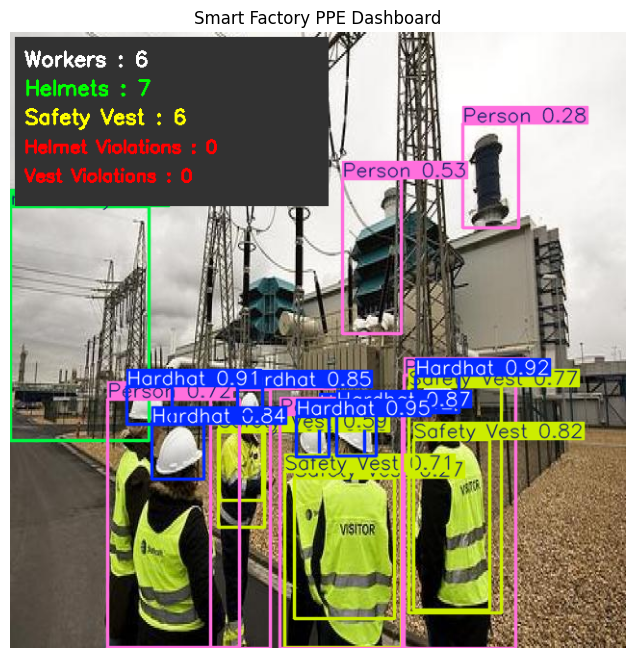

In [ ]:
import matplotlib.pyplot as plt

frame = cv2.cvtColor(frame,
                     cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12,8))

plt.imshow(frame)

plt.axis("off")

plt.title("Smart Factory PPE Dashboard")

plt.show()

In [ ]:
print("="*50)

print("SMART FACTORY PPE REPORT")

print("="*50)

print(f"Workers               : {workers}")

print(f"Helmets              : {helmets}")

print(f"Safety Vests         : {vests}")

print(f"Helmet Violations    : {helmet_violation}")

print(f"Vest Violations      : {vest_violation}")

print("="*50)

SMART FACTORY PPE REPORT
Workers               : 6
Helmets              : 7
Safety Vests         : 6
Helmet Violations    : 0
Vest Violations      : 0
